# 05 — Random Forest | HOG 300 × 225

**Amaç:** 300 × 225 boyutundaki görüntülerden önceden çıkarılan HOG özellikleriyle **Original HOG** ve **Masked HOG** modellerini karşılaştırmak.

- Başlangıç deneyi: **3.000 eğitim görüntüsü**, **1.503 validation görüntüsü** (tam validation seti).
- Aynı görüntü indeksleri iki model için de kullanılır.
- Büyük `.npy` dosyaları `mmap_mode="r"` ile açılır; validation tahminleri parçalara ayrılır.
- **Test seti kullanılmaz.** Bu notebook klinik karar verme amacı taşımaz.

> Not: Bu bölme görüntü bazlıdır. Aynı lezyonun birden fazla görüntüsü varsa hasta/lezyon bazlı veri sızıntısı olabilir. Ayrıca maskeli model gerçek segmentasyon maskelerini gerektirir.

## 1. Ortam ve proje yolları

In [1]:
from pathlib import Path
import sys
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

CURRENT_DIR = Path.cwd()
PROJECT_ROOT = CURRENT_DIR.parent if CURRENT_DIR.name == "notebooks" else CURRENT_DIR
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import BASE_DIR
from src.data_loader import load_dataset

FEATURE_DIR = BASE_DIR / "outputs" / "features"
REPORT_DIR = BASE_DIR / "outputs" / "models" / "rf_300x225_3000train"
REPORT_DIR.mkdir(parents=True, exist_ok=True)
print("Proje:", BASE_DIR)
print("Özellikler:", FEATURE_DIR)
print("Raporlar:", REPORT_DIR)

Proje: C:\Users\Deniz TOZAN\OneDrive - Analythinx Bilişim Hizmetleri Ticaret Anonim Şirketi\WORK\Calismalar\uygulama\Kodlar\Health
Özellikler: C:\Users\Deniz TOZAN\OneDrive - Analythinx Bilişim Hizmetleri Ticaret Anonim Şirketi\WORK\Calismalar\uygulama\Kodlar\Health\outputs\features
Raporlar: C:\Users\Deniz TOZAN\OneDrive - Analythinx Bilişim Hizmetleri Ticaret Anonim Şirketi\WORK\Calismalar\uygulama\Kodlar\Health\outputs\models\rf_300x225_3000train


## 2. Kayıtlı özellikleri yükle ve eşleşmeleri kontrol et

In [2]:
# Bu iki dosya 04_hog_features notebook'unda üretilmiş olmalı.
original_path = FEATURE_DIR / "X_original_hog_300x225.npy"
masked_path = FEATURE_DIR / "X_masked_hog_300x225.npy"

for path in (original_path, masked_path):
    if not path.is_file():
        raise FileNotFoundError(f"HOG dosyası eksik: {path}")

X_original = np.load(original_path, mmap_mode="r")
X_masked = np.load(masked_path, mmap_mode="r")

# Eski y/image_ids .npy dosyaları 'object' olarak kaydedilmiş olabilir.
# Dosyalar proje içinde daha önce kendimizce üretildiği için burada yükleyip
# hemen güvenli string dizisine dönüştürüyoruz. Güvenilmeyen .npy dosyalarıyla kullanmayın.
y = np.asarray(np.load(FEATURE_DIR / "y_labels.npy", allow_pickle=True), dtype=str)
image_ids = np.asarray(np.load(FEATURE_DIR / "image_ids.npy", allow_pickle=True), dtype=str)

assert X_original.shape == X_masked.shape, "Original ve Masked özellik boyutları farklı"
assert X_original.shape == (10015, 34992), f"Beklenmeyen HOG boyutu: {X_original.shape}"
assert X_original.dtype == X_masked.dtype == np.float32
assert len(y) == len(image_ids) == X_original.shape[0]
assert len(np.unique(image_ids)) == len(image_ids), "Tekrarlanan görüntü ID'si var"

# HOG çıktısındaki satırların, etiketlerle aynı sırada olması şart.
df_check = load_dataset()
assert np.array_equal(df_check["image"].astype(str).to_numpy(), image_ids), "image_ids sırası uyuşmuyor"
assert np.array_equal(df_check["label"].astype(str).to_numpy(), y), "y_labels sırası uyuşmuyor"

print("Original:", X_original.shape, X_original.dtype)
print("Masked:  ", X_masked.shape, X_masked.dtype)
print("Etiket ve görüntü eşleşmesi: doğru")

Original: (10015, 34992) float32
Masked:   (10015, 34992) float32
Etiket ve görüntü eşleşmesi: doğru


## 3. Train / Validation / Test ayır (test setini sakla)

In [3]:
from sklearn.model_selection import train_test_split

indices = np.arange(len(y))
dev_idx, test_idx = train_test_split(indices, test_size=0.15, stratify=y, random_state=42)
train_idx, val_idx = train_test_split(dev_idx, test_size=0.15 / 0.85, stratify=y[dev_idx], random_state=42)

# Mevcut anlaşmamız: ilk model deneyini 3.000 eğitim görüntüsüyle yapmak.
train_idx_small, _ = train_test_split(train_idx, train_size=7000, stratify=y[train_idx], random_state=42)

assert not (set(train_idx_small) & set(val_idx))
assert not (set(train_idx_small) & set(test_idx))
assert not (set(val_idx) & set(test_idx))

print(f"Train alt örneklem: {len(train_idx_small)}")
print(f"Validation: {len(val_idx)}")
print(f"Test (dokunulmuyor): {len(test_idx)}")
print("\nEğitim sınıf dağılımı:\n", pd.Series(y[train_idx_small]).value_counts())

Train alt örneklem: 7000
Validation: 1503
Test (dokunulmuyor): 1503

Eğitim sınıf dağılımı:
 NV       4687
MEL       778
BKL       768
BCC       359
AKIEC     229
VASC       99
DF         80
Name: count, dtype: int64


## 4. Basit referans modeli (çoğunluk sınıfı)

In [4]:
from sklearn.metrics import accuracy_score, f1_score

majority_class = pd.Series(y[train_idx_small]).value_counts().idxmax()
baseline_pred = np.repeat(majority_class, len(val_idx))
print("Çoğunluk sınıfı:", majority_class)
print("Baseline validation accuracy:", round(accuracy_score(y[val_idx], baseline_pred), 4))
print("Baseline validation macro F1:", round(f1_score(y[val_idx], baseline_pred, average="macro", zero_division=0), 4))

Çoğunluk sınıfı: NV
Baseline validation accuracy: 0.6693
Baseline validation macro F1: 0.1146


## 5. RF modelini tanımla ve bellek dostu tahmin fonksiyonu

In [5]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_score, recall_score, classification_report, confusion_matrix

# RAM kısıtı nedeniyle başlangıçta daha küçük bir model kullanıyoruz.
RF_PARAMS = dict(
    n_estimators=50,
    max_depth=10,
    min_samples_leaf=5,
    max_features="sqrt",
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=2,
)

def predict_in_batches(model, X_memmap, indices, batch_size=40):
    """memmap'ten yalnızca küçük grupları RAM'e kopyalayarak tahmin et."""
    predictions = []
    for start in range(0, len(indices), batch_size):
        part_idx = indices[start:start + batch_size]
        X_batch = X_memmap[part_idx]
        predictions.extend(model.predict(X_batch))
        del X_batch
    return np.asarray(predictions)

print("RF parametreleri:", RF_PARAMS)

RF parametreleri: {'n_estimators': 50, 'max_depth': 10, 'min_samples_leaf': 5, 'max_features': 'sqrt', 'class_weight': 'balanced_subsample', 'random_state': 42, 'n_jobs': 2}


## 6. Original HOG ve Masked HOG modellerini sırayla eğit

In [6]:
# Bilgisayarın RAM'inde eski büyük X_train/X_val dizileri kalmışsa temizle.
for var_name in ("X_train", "X_val", "X_data"):
    if var_name in globals():
        del globals()[var_name]
gc.collect()

feature_sets = {"Original HOG": X_original, "Masked HOG": X_masked}
results = []
reports = {}
confusion_matrices = {}
trained_models = {}

for model_name, X_memmap in feature_sets.items():
    print(f"\n===== {model_name} =====")
    X_train_batch = X_memmap[train_idx_small]  # Yaklaşık 400 MiB
    print("Eğitim matrisi:", X_train_batch.shape,
          f"({X_train_batch.nbytes / 1024**2:.0f} MiB)")

    model = RandomForestClassifier(**RF_PARAMS)
    model.fit(X_train_batch, y[train_idx_small])
    del X_train_batch
    gc.collect()

    val_pred = predict_in_batches(model, X_memmap, val_idx, batch_size=40)
    train_pred = predict_in_batches(model, X_memmap, train_idx_small, batch_size=40)

    results.append({
        "Model": model_name,
        "Train_Accuracy": accuracy_score(y[train_idx_small], train_pred),
        "Val_Accuracy": accuracy_score(y[val_idx], val_pred),
        "Train_Macro_F1": f1_score(y[train_idx_small], train_pred, average="macro", zero_division=0),
        "Val_Macro_F1": f1_score(y[val_idx], val_pred, average="macro", zero_division=0),
        "Val_Macro_Precision": precision_score(y[val_idx], val_pred, average="macro", zero_division=0),
        "Val_Macro_Recall": recall_score(y[val_idx], val_pred, average="macro", zero_division=0),
        "Predicted_Classes": len(np.unique(val_pred)),
    })
    class_names = np.unique(y)
    confusion_matrices[model_name] = confusion_matrix(y[val_idx], val_pred, labels=class_names)
    reports[model_name] = classification_report(y[val_idx], val_pred, labels=class_names, zero_division=0)
    trained_models[model_name] = model
    print(reports[model_name])

results_df = pd.DataFrame(results)
display(results_df)


===== Original HOG =====
Eğitim matrisi: (7000, 34992) (934 MiB)
              precision    recall  f1-score   support

       AKIEC       0.22      0.04      0.07        49
         BCC       0.00      0.00      0.00        77
         BKL       0.17      0.20      0.18       165
          DF       0.00      0.00      0.00        18
         MEL       0.14      0.13      0.13       167
          NV       0.70      0.77      0.73      1006
        VASC       0.00      0.00      0.00        21

    accuracy                           0.56      1503
   macro avg       0.17      0.16      0.16      1503
weighted avg       0.51      0.56      0.53      1503


===== Masked HOG =====
Eğitim matrisi: (7000, 34992) (934 MiB)
              precision    recall  f1-score   support

       AKIEC       0.08      0.06      0.07        49
         BCC       0.13      0.09      0.11        77
         BKL       0.19      0.30      0.23       165
          DF       0.00      0.00      0.00        18
  

,Model,Train_Accuracy,Val_Accuracy,Train_Macro_F1,Val_Macro_F1,Val_Macro_Precision,Val_Macro_Recall,Predicted_Classes
0,Original HOG,0.916143,0.555556,0.934251,0.159469,0.174839,0.162988,5
1,Masked HOG,0.802857,0.517631,0.833820,0.211789,0.215430,0.216919,6


## 7. Validation ve eğitim performansını karşılaştır

,Model,Train_Accuracy,Val_Accuracy,Train_Macro_F1,Val_Macro_F1,Val_Macro_Precision,Val_Macro_Recall,Predicted_Classes
1,Masked HOG,0.802857,0.517631,0.833820,0.211789,0.215430,0.216919,6
0,Original HOG,0.916143,0.555556,0.934251,0.159469,0.174839,0.162988,5


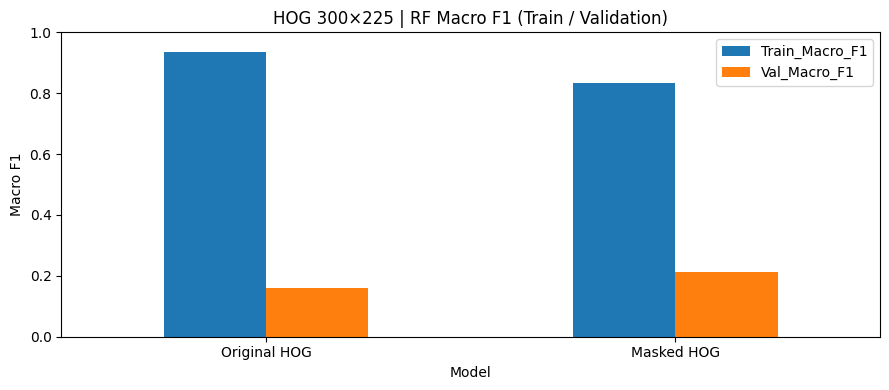

In [15]:
display(results_df.sort_values("Val_Macro_F1", ascending=False))

ax = results_df.set_index("Model")[["Train_Macro_F1", "Val_Macro_F1"]].plot(kind="bar", figsize=(9, 4))
ax.set_title("HOG 300×225 | RF Macro F1 (Train / Validation)")
ax.set_ylim(0, 1)
ax.set_ylabel("Macro F1")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 8. Confusion Matrix: ham sayılar ve satır bazında normalize edilmiş yüzdeler

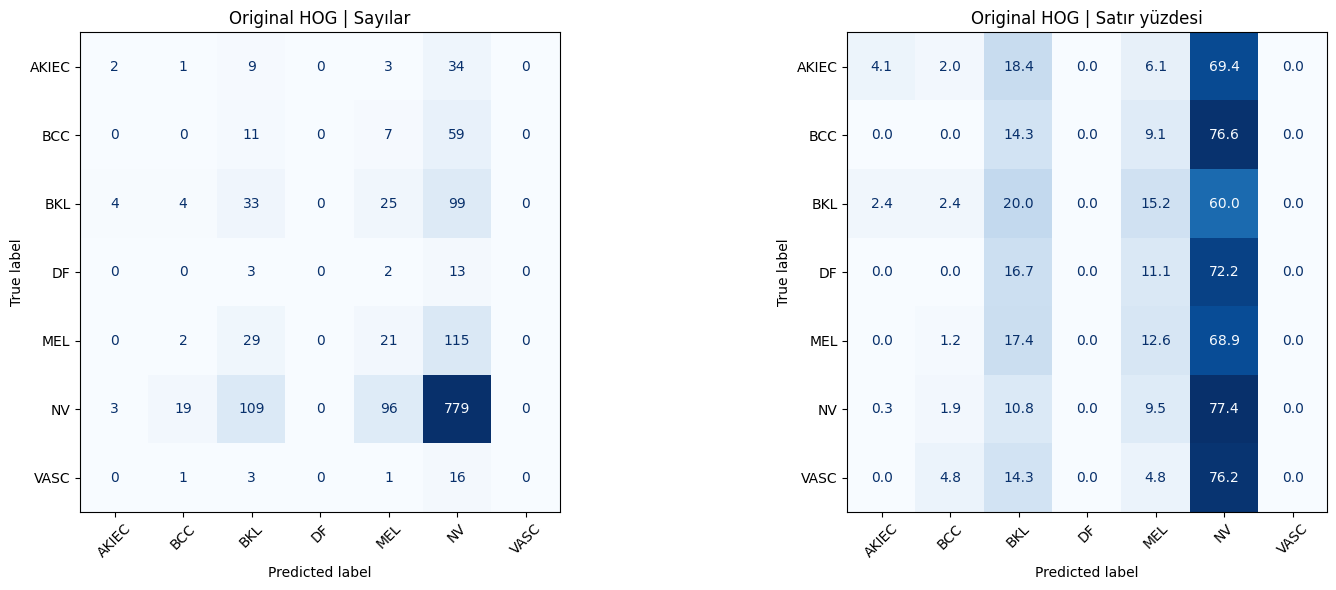

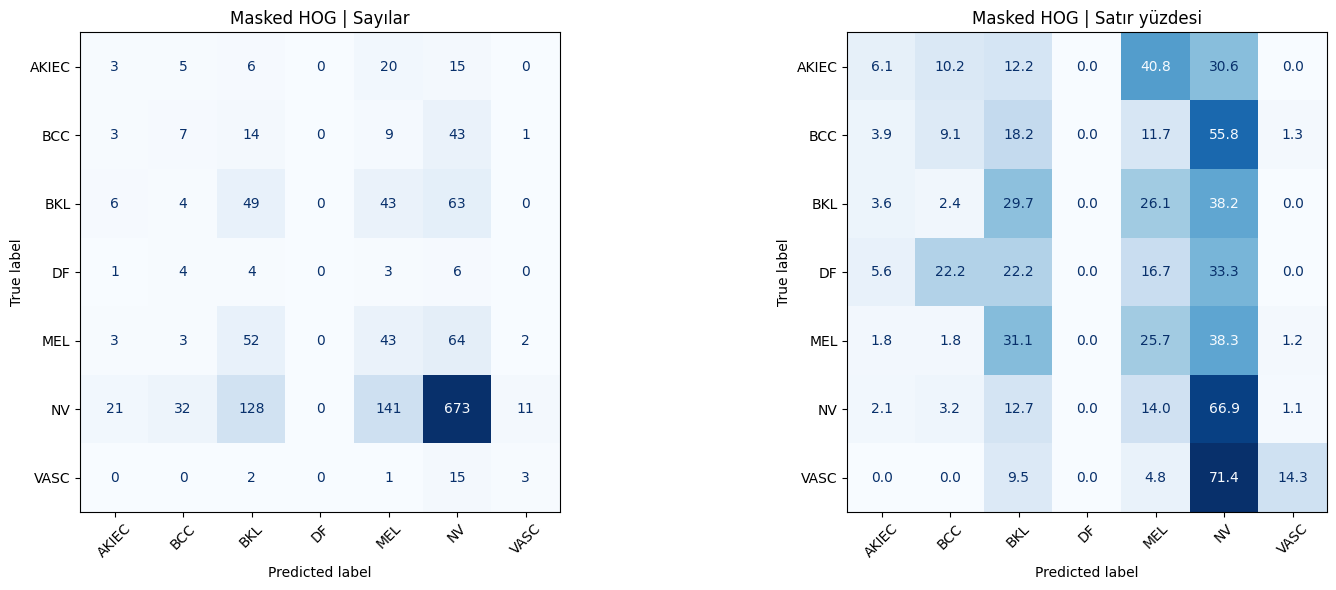

In [16]:
from sklearn.metrics import ConfusionMatrixDisplay

class_names = np.unique(y)
for model_name, cm in confusion_matrices.items():
    cm_percent = (cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)) * 100
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    ConfusionMatrixDisplay(cm, display_labels=class_names).plot(ax=axes[0], cmap="Blues", values_format="d", colorbar=False)
    ConfusionMatrixDisplay(cm_percent, display_labels=class_names).plot(ax=axes[1], cmap="Blues", values_format=".1f", colorbar=False)
    axes[0].set_title(f"{model_name} | Sayılar")
    axes[1].set_title(f"{model_name} | Satır yüzdesi")
    for ax in axes:
        ax.tick_params(axis="x", rotation=45)
    plt.tight_layout()
    plt.show()

## 9. Sonuç tablolarını kaydet

In [17]:
results_df.to_csv(REPORT_DIR / "rf_metrics.csv", index=False)
for model_name, cm in confusion_matrices.items():
    slug = "original" if model_name == "Original HOG" else "masked"
    pd.DataFrame(cm, index=class_names, columns=class_names).to_csv(REPORT_DIR / f"confusion_matrix_{slug}.csv")
    (REPORT_DIR / f"classification_report_{slug}.txt").write_text(reports[model_name], encoding="utf-8")
print("Raporlar kaydedildi:", REPORT_DIR)
print("Test verisi kullanılmadı.")

Raporlar kaydedildi: C:\Users\Deniz TOZAN\OneDrive - Analythinx Bilişim Hizmetleri Ticaret Anonim Şirketi\WORK\Calismalar\uygulama\Kodlar\Health\outputs\models\rf_300x225_3000train
Test verisi kullanılmadı.
